# Imitation Learning: Behavior Cloning & DAgger

**Topics:** Behavior Cloning | Distribution Shift | DAgger

**Environment:** Custom 2D S-curve continuous control task

## 1. Environment & Expert Policy

### Environment

We use a custom 2D continuous-control task (`SCurve2DEnv`). An agent must navigate from a start position to a goal along an S-shaped reference curve. The state is $[x, y, v_x, v_y]$ and the action is a 2D acceleration $[a_x, a_y]$ clipped to $\pm a_\text{max}$. The observation also includes the goal position and several lookahead reference points.

### Expert Policy

The expert is a **PD (Proportional–Derivative) tracking controller** with lookahead. At every step it:

1. Picks a target point from the furthest lookahead reference
2. Computes a desired velocity $v_\text{des}$ along the path tangent
3. Applies PD control: $a = k_p \, (\text{target} - \text{pos}) + k_d \, (v_\text{des} - v)$
4. Clips the result to $[-a_\text{max}, a_\text{max}]$

The expert is deterministic — all variation across episodes comes from small Gaussian noise on initial position and velocity at `reset`.

In [1]:
import numpy as np
from dataclasses import dataclass

try:
    import gymnasium as gym
    from gymnasium import spaces
except ImportError:
    import gym
    from gym import spaces

from IPython.display import clear_output
import time
import matplotlib.pyplot as plt
from tqdm import tqdm

In [2]:
@dataclass
class SCurveConfig:
    dt: float = 0.05
    episode_seconds: float = 12.0
    a_max: float = 3.0
    v_max: float = 4.0
    x_start: float = 0.0
    x_goal: float = 10.0
    y_center: float = 0.0
    y_amp: float = 2.0
    s_turns: float = 1.0
    goal_radius: float = 0.25
    max_track_error: float = 4.0
    lookahead_k: int = 2
    lookahead_dt: float = 0.25
    pos_noise: float = 0.05
    vel_noise: float = 0.05


class SCurve2DEnv(gym.Env):
    metadata = {"render_modes": ["human"], "render_fps": 30}

    def __init__(self, config: SCurveConfig = SCurveConfig(), render_mode=None):
        super().__init__()
        self.cfg = config
        self.render_mode = render_mode
        self.dt = self.cfg.dt
        self.T = self.cfg.episode_seconds
        self.max_steps = int(np.ceil(self.T / self.dt))
        self.action_space = spaces.Box(
            low=-self.cfg.a_max, high=self.cfg.a_max, shape=(2,), dtype=np.float32
        )
        obs_dim = 4 + 2 + 2 * (1 + self.cfg.lookahead_k)
        high = np.full((obs_dim,), np.inf, dtype=np.float32)
        self.observation_space = spaces.Box(-high, high, dtype=np.float32)
        self.state = None
        self.step_count = 0
        self.t = 0.0
        self.u = 0.0
        self._fig = None
        self._ax = None
        self._artist_agent = None
        self._artist_path = None
        self._artist_ref = None

    def _path_xy(self, u: float) -> np.ndarray:
        u = np.clip(u, 0.0, 1.0)
        x = self.cfg.x_start + (self.cfg.x_goal - self.cfg.x_start) * u
        y = self.cfg.y_center + self.cfg.y_amp * np.sin(2.0 * np.pi * self.cfg.s_turns * u)
        return np.array([x, y], dtype=np.float32)

    def _path_tangent(self, u: float) -> np.ndarray:
        u = np.clip(u, 0.0, 1.0)
        dx_du = (self.cfg.x_goal - self.cfg.x_start)
        dy_du = self.cfg.y_amp * (2.0 * np.pi * self.cfg.s_turns) * np.cos(2.0 * np.pi * self.cfg.s_turns * u)
        return np.array([dx_du, dy_du], dtype=np.float32)

    def _path_curvature(self, u: float) -> float:
        u = np.clip(u, 0.0, 1.0)
        L = self.cfg.x_goal - self.cfg.x_start
        omega = 2.0 * np.pi * self.cfg.s_turns
        dy_du = self.cfg.y_amp * omega * np.cos(omega * u)
        d2y_du2 = -self.cfg.y_amp * omega ** 2 * np.sin(omega * u)
        return abs(L * d2y_du2) / ((L ** 2 + dy_du ** 2) ** 1.5 + 1e-8)

    def _estimate_progress_from_pos(self, pos: np.ndarray) -> float:
        x = pos[0]
        u = (x - self.cfg.x_start) / (self.cfg.x_goal - self.cfg.x_start)
        return float(np.clip(u, 0.0, 1.0))

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.step_count = 0
        self.t = 0.0
        start = self._path_xy(0.0)
        pos = start + self.np_random.normal(0.0, self.cfg.pos_noise, size=(2,)).astype(np.float32)
        vel = self.np_random.normal(0.0, self.cfg.vel_noise, size=(2,)).astype(np.float32)
        self.state = np.concatenate([pos, vel]).astype(np.float32)
        self.u = self._estimate_progress_from_pos(pos)
        obs = self._get_obs()
        info = self._get_info()
        if self.render_mode == "human":
            self.render()
        return obs, info

    def step(self, action):
        action = np.asarray(action, dtype=np.float32)
        action = np.clip(action, -self.cfg.a_max, self.cfg.a_max)
        x, y, vx, vy = self.state
        vx = vx + action[0] * self.dt
        vy = vy + action[1] * self.dt
        v = np.array([vx, vy], dtype=np.float32)
        speed = np.linalg.norm(v) + 1e-8
        if speed > self.cfg.v_max:
            v = v * (self.cfg.v_max / speed)
        vx, vy = float(v[0]), float(v[1])
        x = x + vx * self.dt
        y = y + vy * self.dt
        self.state = np.array([x, y, vx, vy], dtype=np.float32)
        self.step_count += 1
        self.t = self.step_count * self.dt
        self.u = self._estimate_progress_from_pos(self.state[:2])
        ref = self._path_xy(self._u_ref())
        track_err = np.linalg.norm(self.state[:2] - ref)
        reward = -track_err
        goal = self._path_xy(1.0)
        dist_to_goal = np.linalg.norm(self.state[:2] - goal)
        terminated = dist_to_goal <= self.cfg.goal_radius
        truncated = (self.step_count >= self.max_steps)
        if track_err > self.cfg.max_track_error:
            truncated = True
        obs = self._get_obs()
        info = self._get_info()
        info.update({
            "track_err": float(track_err),
            "u": float(self.u),
            "u_ref": float(self._u_ref()),
            "dist_to_goal": float(dist_to_goal),
        })
        if self.render_mode == "human":
            self.render()
        return obs, reward, terminated, truncated, info

    def _u_ref(self) -> float:
        return float(np.clip(self.t / self.T, 0.0, 1.0))

    def _get_obs(self) -> np.ndarray:
        pos = self.state[:2]
        vel = self.state[2:]
        goal = self._path_xy(1.0)
        refs = [self._path_xy(self._u_ref())]
        for k in range(1, self.cfg.lookahead_k + 1):
            u_k = np.clip((self.t + k * self.cfg.lookahead_dt) / self.T, 0.0, 1.0)
            refs.append(self._path_xy(u_k))
        refs = np.concatenate(refs, axis=0)
        obs = np.concatenate([pos, vel, goal, refs]).astype(np.float32)
        return obs

    def _get_info(self):
        return {}

    def expert_policy(self, obs: np.ndarray) -> np.ndarray:
        obs = np.asarray(obs, dtype=np.float32)
        pos = obs[0:2]
        vel = obs[2:4]
        goal = obs[4:6]
        refs_flat = obs[6:]
        refs = refs_flat.reshape(-1, 2)
        far_ref = refs[-1]
        n = len(refs)
        w = np.arange(1.0, n + 1.0)
        w /= w.sum()
        target = (refs * w[:, None]).sum(axis=0)
        u_far = self._estimate_progress_from_pos(far_ref)
        curvature = self._path_curvature(u_far)
        v_base = 2.5
        v_des_mag = v_base / (1.0 + 10.0 * curvature)
        dist_to_goal = np.linalg.norm(goal - pos)
        if dist_to_goal < 1.5:
            v_des_mag *= float(np.clip(dist_to_goal / 1.5, 0.2, 1.0))
        tan = self._path_tangent(u_far)
        direction = tan / (np.linalg.norm(tan) + 1e-8)
        v_des = direction * v_des_mag
        kp = 6.0
        kd = 3.0
        a = kp * (target - pos) + kd * (v_des - vel)
        a = np.clip(a, -self.cfg.a_max, self.cfg.a_max).astype(np.float32)
        return a

    def render(self):
        import matplotlib.pyplot as plt
        if self._fig is None:
            self._fig, self._ax = plt.subplots(figsize=(6, 4))
            self._ax.set_aspect("equal", adjustable="box")
            self._ax.set_title("SCurve2DEnv")
            self._ax.set_xlabel("x")
            self._ax.set_ylabel("y")
            us = np.linspace(0, 1, 200)
            path = np.stack([self._path_xy(u) for u in us], axis=0)
            (self._artist_path,) = self._ax.plot(path[:, 0], path[:, 1], linewidth=2)
            (self._artist_agent,) = self._ax.plot([], [], marker="o", markersize=8)
            (self._artist_ref,) = self._ax.plot([], [], marker="x", markersize=8)
            self._ax.set_xlim(self.cfg.x_start - 1.0, self.cfg.x_goal + 1.0)
            self._ax.set_ylim(self.cfg.y_center - (self.cfg.y_amp + 3.0), self.cfg.y_center + (self.cfg.y_amp + 3.0))
        pos = self.state[:2]
        ref = self._path_xy(self._u_ref())
        self._artist_agent.set_data([pos[0]], [pos[1]])
        self._artist_ref.set_data([ref[0]], [ref[1]])
        self._ax.figure.canvas.draw()
        self._ax.figure.canvas.flush_events()

    def close(self):
        if self._fig is not None:
            import matplotlib.pyplot as plt
            plt.close(self._fig)
            self._fig = None
            self._ax = None

In [3]:
env = SCurve2DEnv(render_mode=None)
obs, info = env.reset(seed=0)
total = 0.0
for _ in range(200):
    a = env.expert_policy(obs)
    obs, r, term, trunc, info = env.step(a)
    total += r
    if term or trunc:
        break
print("done:", term, trunc, "steps:", env.step_count, "u:", info.get("u"), "total reward:", total)

done: False False steps: 200 u: 0.8395782470703125 total reward: -41.84662833344191


Episode ended at step 231 terminated: True truncated: False


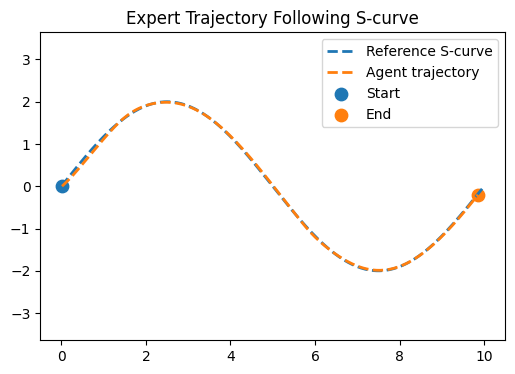

In [4]:
from matplotlib import lines

env = SCurve2DEnv(render_mode=None)
obs, _ = env.reset(seed=0)
states = []

for t in tqdm(range(400), desc="Collecting expert trajectory"):
    action = env.expert_policy(obs)
    obs, r, terminated, truncated, info = env.step(action)
    states.append(env.state[:2].copy())
    if terminated or truncated:
        print("Episode ended at step", t, "terminated:", terminated, "truncated:", truncated)
        break

states = np.array(states)
us = np.linspace(0, 1, 300)
ref_path = np.stack([env._path_xy(u) for u in us])

plt.figure(figsize=(6,4))
plt.plot(ref_path[:,0], ref_path[:,1], linewidth=2, label="Reference S-curve",linestyle="--")
plt.plot(states[:,0], states[:,1], linewidth=2, label="Agent trajectory", linestyle="--")
plt.scatter(states[0,0], states[0,1], s=80, label="Start")
plt.scatter(states[-1,0], states[-1,1], s=80, label="End")
plt.legend()
plt.axis("equal")
plt.title("Expert Trajectory Following S-curve")
plt.show()

---
## 2. Behavior Cloning

**Behavior Cloning (BC)** treats imitation learning as supervised learning:

1. **Collect** a dataset of (observation, action) pairs from the expert
2. **Train** a policy $\pi_\theta(o)$ to minimize $\| \pi_\theta(o) - a_{\text{expert}} \|^2$
3. **Evaluate** in the environment

Key limitation: **distribution shift** — errors compound at test time as the learner visits states it never saw during training.

### Step 1 — Collect Expert Demonstrations

In [5]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

def collect_expert_data(env, n_episodes=50, seed_start=0):
    """Roll out the expert policy and store (obs, action) pairs."""
    all_obs, all_act = [], []
    for ep in range(n_episodes):
        obs, _ = env.reset(seed=seed_start + ep)
        done = False
        while not done:
            action = env.expert_policy(obs)
            all_obs.append(obs.copy())
            all_act.append(action.copy())
            obs, _, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
    return np.array(all_obs, dtype=np.float32), np.array(all_act, dtype=np.float32)

env = SCurve2DEnv(render_mode=None)
expert_obs, expert_act = collect_expert_data(env, n_episodes=50)
print(f"Collected {len(expert_obs)} transitions from {50} episodes")
print(f"Observation shape: {expert_obs.shape},  Action shape: {expert_act.shape}")

Collected 11600 transitions from 50 episodes
Observation shape: (11600, 12),  Action shape: (11600, 2)


### Step 2 — BC Policy Network

In [6]:
class BCPolicy(nn.Module):
    """Simple MLP policy: obs -> action."""

    def __init__(self, obs_dim, act_dim, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, act_dim),
        )

    def forward(self, obs):
        return self.net(obs)

obs_dim = expert_obs.shape[1]
act_dim = expert_act.shape[1]

bc_policy = BCPolicy(obs_dim, act_dim)
print(bc_policy)
print(f"Parameters: {sum(p.numel() for p in bc_policy.parameters()):,}")

BCPolicy(
  (net): Sequential(
    (0): Linear(in_features=12, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)
Parameters: 18,434


### Step 3 — Train BC Policy

In [7]:
def train_bc(policy, obs, act, epochs=80, batch_size=256, lr=1e-3):
    """Train policy with MSE loss on expert (obs, act) pairs."""
    dataset = TensorDataset(torch.tensor(obs), torch.tensor(act))
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

    optimizer = optim.Adam(policy.parameters(), lr=lr)
    loss_fn = nn.MSELoss()

    history = []
    for epoch in tqdm(range(1, epochs + 1), desc="Training BC policy"):
        epoch_loss = 0.0
        n_batches = 0
        for ob, ac in loader:
            pred = policy(ob)
            loss = loss_fn(pred, ac)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
            n_batches += 1
        avg = epoch_loss / n_batches
        history.append(avg)
        if epoch % 20 == 0 or epoch == 1:
            print(f"  epoch {epoch:3d}/{epochs}  loss = {avg:.6f}")
    return history

bc_loss_history = train_bc(bc_policy, expert_obs, expert_act)

Training BC policy:   0%|          | 0/80 [00:00<?, ?it/s]


Training BC policy:   2%|▎         | 2/80 [00:00<00:06, 12.52it/s]


Training BC policy:   5%|▌         | 4/80 [00:00<00:05, 14.24it/s]


  epoch   1/80  loss = 0.312056


Training BC policy:   8%|▊         | 6/80 [00:00<00:04, 15.59it/s]


Training BC policy:  10%|█         | 8/80 [00:00<00:04, 16.32it/s]


... (37 outputs left out)

Training BC policy:  98%|█████████▊| 78/80 [00:04<00:00, 17.57it/s]


Training BC policy: 100%|██████████| 80/80 [00:04<00:00, 17.57it/s]


Training BC policy: 100%|██████████| 80/80 [00:04<00:00, 17.04it/s]


  epoch  80/80  loss = 0.001263


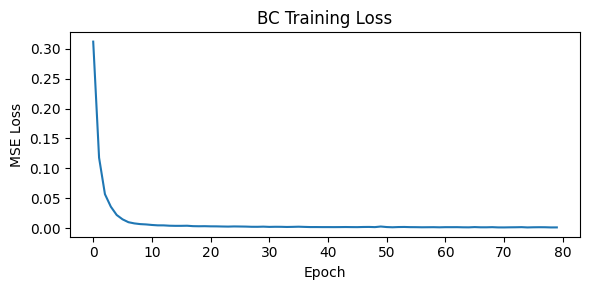

In [8]:
plt.figure(figsize=(6, 3))
plt.plot(bc_loss_history)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("BC Training Loss")
plt.tight_layout()
plt.show()

### Step 4 — Evaluate BC Policy

In [9]:
@torch.no_grad()
def rollout(env, policy_fn, seed=0, max_steps=500):
    """Roll out a policy and return states, rewards, info."""
    obs, _ = env.reset(seed=seed)
    states, rewards = [env.state[:2].copy()], []
    for _ in range(max_steps):
        action = policy_fn(obs)
        obs, r, terminated, truncated, info = env.step(action)
        states.append(env.state[:2].copy())
        rewards.append(r)
        if terminated or truncated:
            break
    return np.array(states), np.sum(rewards), info

def bc_policy_fn(obs):
    t = torch.tensor(obs, dtype=torch.float32).unsqueeze(0)
    a = bc_policy(t).squeeze(0).numpy()
    return np.clip(a, -env.cfg.a_max, env.cfg.a_max)

env = SCurve2DEnv(render_mode=None)

n_eval = 20
expert_rewards, bc_rewards = [], []
for s in range(n_eval):
    _, er, _ = rollout(env, env.expert_policy, seed=1000 + s)
    _, br, _ = rollout(env, bc_policy_fn, seed=1000 + s)
    expert_rewards.append(er)
    bc_rewards.append(br)

print(f"Expert  — mean reward: {np.mean(expert_rewards):.2f} ± {np.std(expert_rewards):.2f}")
print(f"BC      — mean reward: {np.mean(bc_rewards):.2f} ± {np.std(bc_rewards):.2f}")

Expert  — mean reward: -49.92 ± 0.46
BC      — mean reward: -55.71 ± 3.26


### Step 5 — Visualize Expert vs BC Trajectories

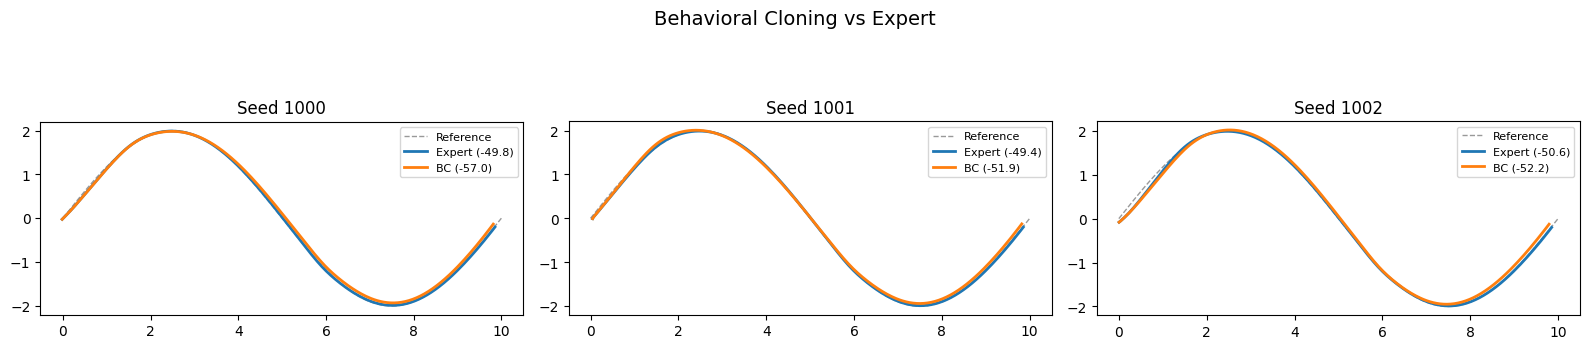

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

us = np.linspace(0, 1, 300)
ref_path = np.stack([env._path_xy(u) for u in us])

seeds_to_show = [1000, 1001, 1002]
for ax, seed in zip(axes, seeds_to_show):
    expert_states, er, _ = rollout(env, env.expert_policy, seed=seed)
    bc_states, br, _ = rollout(env, bc_policy_fn, seed=seed)

    ax.plot(ref_path[:, 0], ref_path[:, 1], "k--", linewidth=1, alpha=0.4, label="Reference")
    ax.plot(expert_states[:, 0], expert_states[:, 1], linewidth=2, label=f"Expert ({er:.1f})")
    ax.plot(bc_states[:, 0], bc_states[:, 1], linewidth=2, label=f"BC ({br:.1f})")
    ax.set_title(f"Seed {seed}")
    ax.set_aspect("equal", adjustable="box")
    ax.legend(fontsize=8)

fig.suptitle("Behavioral Cloning vs Expert", fontsize=14)
plt.tight_layout()
plt.show()

---
## 3. Distribution Shift Analysis

BC only sees states the expert visits. When the agent starts far from the training distribution, small errors compound and the policy degrades.

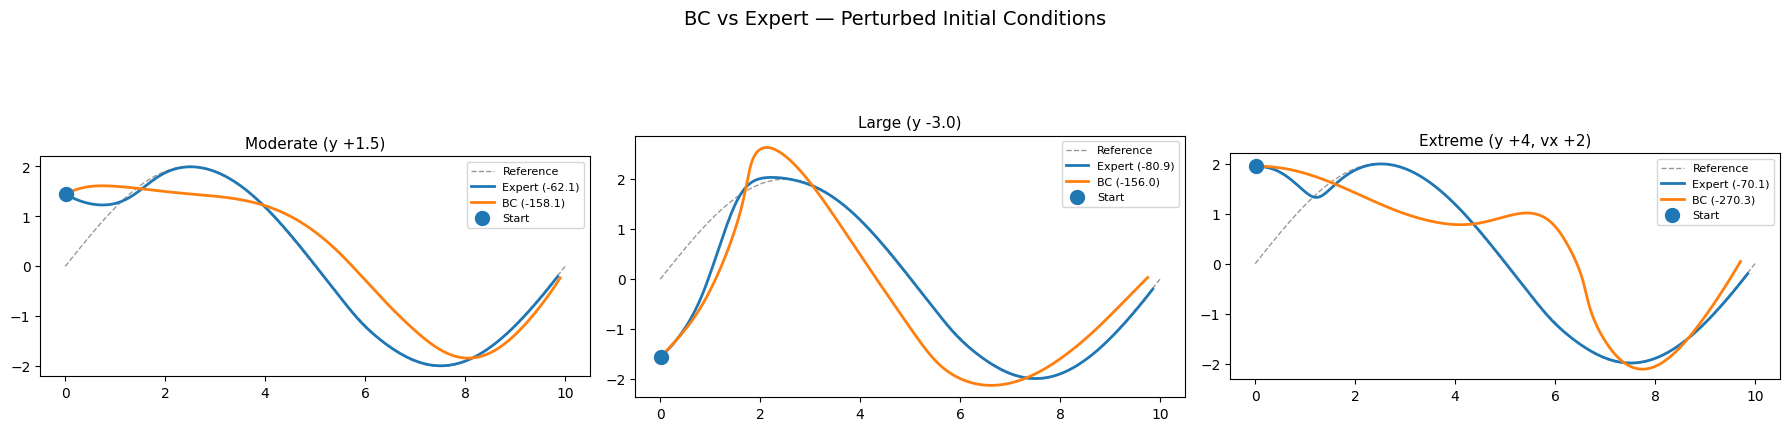

In [11]:
@torch.no_grad()
def rollout_perturbed(env, policy_fn, seed=0, pos_offset=None, vel_offset=None, max_steps=500):
    """Like rollout(), but injects a large perturbation into the initial state."""
    obs, _ = env.reset(seed=seed)
    if pos_offset is not None:
        env.state[0] += pos_offset[0]
        env.state[1] += pos_offset[1]
    if vel_offset is not None:
        env.state[2] += vel_offset[0]
        env.state[3] += vel_offset[1]
    env.u = env._estimate_progress_from_pos(env.state[:2])
    obs = env._get_obs()

    states, rewards = [env.state[:2].copy()], []
    for _ in range(max_steps):
        action = policy_fn(obs)
        obs, r, terminated, truncated, info = env.step(action)
        states.append(env.state[:2].copy())
        rewards.append(r)
        if terminated or truncated:
            break
    return np.array(states), np.sum(rewards), info

env = SCurve2DEnv(render_mode=None)
us_ref = np.linspace(0, 1, 300)
ref_path = np.stack([env._path_xy(u) for u in us_ref])

perturbations = [
    {"label": "Moderate (y +1.5)",   "pos": np.array([0.0,  1.5]), "vel": None},
    {"label": "Large (y -3.0)",      "pos": np.array([0.0, -1.5]), "vel": None},
    {"label": "Extreme (y +4, vx +2)", "pos": np.array([0.0, 2.0]), "vel": np.array([2.0, 0.0])},
]

fig, axes = plt.subplots(1, len(perturbations), figsize=(6 * len(perturbations), 5))

for ax, pert in zip(axes, perturbations):
    expert_states, er, _ = rollout_perturbed(
        env, env.expert_policy, seed=42,
        pos_offset=pert["pos"], vel_offset=pert["vel"],
    )
    bc_states, br, _ = rollout_perturbed(
        env, bc_policy_fn, seed=42,
        pos_offset=pert["pos"], vel_offset=pert["vel"],
    )

    ax.plot(ref_path[:, 0], ref_path[:, 1], "k--", lw=1, alpha=0.4, label="Reference")
    ax.plot(expert_states[:, 0], expert_states[:, 1], lw=2, label=f"Expert ({er:.1f})")
    ax.plot(bc_states[:, 0], bc_states[:, 1], lw=2, label=f"BC ({br:.1f})")
    ax.scatter(*expert_states[0], marker="o", s=100, zorder=5, label="Start")
    ax.set_title(pert["label"], fontsize=11)
    ax.set_aspect("equal", adjustable="box")
    ax.legend(fontsize=8, loc="best")

fig.suptitle("BC vs Expert — Perturbed Initial Conditions", fontsize=14)
plt.tight_layout()
plt.show()

In [12]:
large_offset = np.array([0.0, -3.0])
n_eval = 20

expert_rew_perturbed, bc_rew_perturbed = [], []
for s in range(n_eval):
    _, er, _ = rollout_perturbed(env, env.expert_policy, seed=3000 + s, pos_offset=large_offset)
    _, br, _ = rollout_perturbed(env, bc_policy_fn, seed=3000 + s, pos_offset=large_offset)
    expert_rew_perturbed.append(er)
    bc_rew_perturbed.append(br)

print("=== Perturbed initial conditions (y offset = -3.0) ===")
print(f"Expert — mean reward: {np.mean(expert_rew_perturbed):.2f} ± {np.std(expert_rew_perturbed):.2f}")
print(f"BC     — mean reward: {np.mean(bc_rew_perturbed):.2f} ± {np.std(bc_rew_perturbed):.2f}")
print()
print("=== Normal initial conditions (for reference) ===")
print(f"Expert — mean reward: {np.mean(expert_rewards):.2f} ± {np.std(expert_rewards):.2f}")
print(f"BC     — mean reward: {np.mean(bc_rewards):.2f} ± {np.std(bc_rewards):.2f}")
print()
gap_normal = np.mean(expert_rewards) - np.mean(bc_rewards)
gap_perturbed = np.mean(expert_rew_perturbed) - np.mean(bc_rew_perturbed)
print(f"Reward gap (expert - BC):  normal = {gap_normal:.2f},  perturbed = {gap_perturbed:.2f}")
print(f"The gap widens by {gap_perturbed / max(gap_normal, 1e-8):.1f}x under perturbation.")

=== Perturbed initial conditions (y offset = -3.0) ===
Expert — mean reward: -135.66 ± 2.55
BC     — mean reward: -326.23 ± 8.98
=== Normal initial conditions (for reference) ===
Expert — mean reward: -49.92 ± 0.46
BC     — mean reward: -55.71 ± 3.26
Reward gap (expert - BC):  normal = 5.79,  perturbed = 190.57
The gap widens by 32.9x under perturbation.


---
## 4. Noisy Execution

Even without initial perturbation, small persistent execution noise can push the learner off the training distribution, causing accumulating errors over time. DAgger is a standard fix: it expands the training dataset toward the learner-induced state distribution.

In [13]:
VEL_NOISE_STD = 0.1

@torch.no_grad()
def rollout_noisy(env, policy_fn, seed=0, vel_noise_std=VEL_NOISE_STD, max_steps=500):
    """Roll out a policy with velocity noise injected at every transition."""
    obs, _ = env.reset(seed=seed)
    rng = np.random.RandomState(seed + 10_000)
    states, rewards = [env.state[:2].copy()], []
    for _ in range(max_steps):
        action = policy_fn(obs)
        obs, r, terminated, truncated, info = env.step(action)
        env.state[2:4] += rng.normal(0, vel_noise_std, size=2).astype(np.float32)
        obs = env._get_obs()
        states.append(env.state[:2].copy())
        rewards.append(r)
        if terminated or truncated:
            break
    return np.array(states), np.sum(rewards), info

env = SCurve2DEnv(render_mode=None)
n_eval = 20

expert_noisy_rews, bc_noisy_rews = [], []
for s in range(n_eval):
    _, er, _ = rollout_noisy(env, env.expert_policy, seed=2000 + s)
    _, br, _ = rollout_noisy(env, bc_policy_fn, seed=2000 + s)
    expert_noisy_rews.append(er)
    bc_noisy_rews.append(br)

print(f"=== Noisy execution (vel_noise_std = {VEL_NOISE_STD}) ===")
print(f"Expert — mean reward: {np.mean(expert_noisy_rews):.2f} ± {np.std(expert_noisy_rews):.2f}")
print(f"BC     — mean reward: {np.mean(bc_noisy_rews):.2f} ± {np.std(bc_noisy_rews):.2f}")

gap_clean = abs(np.mean(expert_rewards) - np.mean(bc_rewards))
gap_noisy = abs(np.mean(expert_noisy_rews) - np.mean(bc_noisy_rews))
print(f"\nReward gap |expert − BC|:  clean = {gap_clean:.2f},  noisy = {gap_noisy:.2f}")
if gap_clean > 0:
    print(f"The gap widens by {gap_noisy / gap_clean:.1f}x under noisy execution.")

=== Noisy execution (vel_noise_std = 0.1) ===
Expert — mean reward: -56.51 ± 2.97
BC     — mean reward: -206.88 ± 83.25
Reward gap |expert − BC|:  clean = 5.79,  noisy = 150.36
The gap widens by 26.0x under noisy execution.


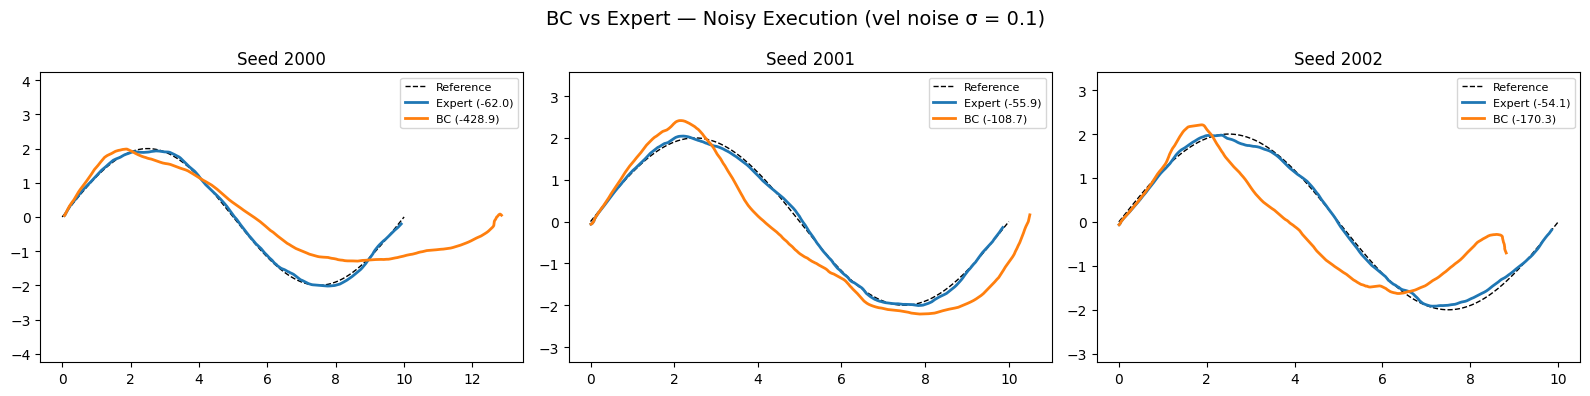

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
us = np.linspace(0, 1, 300)
ref_path = np.stack([env._path_xy(u) for u in us])

for ax, seed in zip(axes, [2000, 2001, 2002]):
    expert_states, er, _ = rollout_noisy(env, env.expert_policy, seed=seed)
    bc_states, br, _ = rollout_noisy(env, bc_policy_fn, seed=seed)

    ax.plot(ref_path[:, 0], ref_path[:, 1], "k--", lw=1, label="Reference")
    ax.plot(expert_states[:, 0], expert_states[:, 1], lw=2, label=f"Expert ({er:.1f})")
    ax.plot(bc_states[:, 0], bc_states[:, 1], lw=2, label=f"BC ({br:.1f})")
    ax.legend(fontsize=8)
    ax.set_title(f"Seed {seed}")
    ax.axis("equal")

fig.suptitle(
    f"BC vs Expert — Noisy Execution (vel noise σ = {VEL_NOISE_STD})", fontsize=14
)
plt.tight_layout()
plt.show()

---
## 5. DAgger — Dataset Aggregation

**DAgger** (Ross et al., 2011) closes the distribution gap iteratively:

| Step | Description |
|------|-------------|
| **1. Train** | Train policy $\hat\pi_i$ on aggregated dataset $\mathcal{D}_i$ |
| **2. Roll out** | Execute $\hat\pi_i$ to visit learner-induced states |
| **3. Label** | Query expert for correct action at each visited state |
| **4. Aggregate** | $\mathcal{D}_{i+1} = \mathcal{D}_i \cup \{(s_t, a^*_t)\}$ |

Each iteration, training data progressively covers the states the learner actually visits at test time.

In [15]:
def _train_silent(policy, obs_np, act_np, epochs=40, batch_size=256, lr=1e-3):
    dataset = TensorDataset(torch.tensor(obs_np), torch.tensor(act_np))
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
    optimizer = optim.Adam(policy.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    final_loss = 0.0
    for epoch in range(1, epochs + 1):
        epoch_loss, n = 0.0, 0
        for ob, ac in loader:
            loss = loss_fn(policy(ob), ac)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
            n += 1
        final_loss = epoch_loss / n
    return final_loss


N_DAGGER_ITERS = 6
N_EPISODES_PER_ITER = 20
DAGGER_EPOCHS = 40

env = SCurve2DEnv(render_mode=None)

agg_obs = [expert_obs.copy()]
agg_act = [expert_act.copy()]

dagger_policy = BCPolicy(obs_dim, act_dim)
dagger_iter_rewards = []

print(f"Running DAgger ({N_DAGGER_ITERS} iterations, "
      f"{N_EPISODES_PER_ITER} episodes/iter, vel_noise σ = {VEL_NOISE_STD})\n")

for it in range(N_DAGGER_ITERS):
    all_obs_np = np.concatenate(agg_obs, axis=0)
    all_act_np = np.concatenate(agg_act, axis=0)
    final_loss = _train_silent(dagger_policy, all_obs_np, all_act_np,
                               epochs=DAGGER_EPOCHS)

    @torch.no_grad()
    def dagger_policy_fn(obs):
        t = torch.tensor(obs, dtype=torch.float32).unsqueeze(0)
        return np.clip(dagger_policy(t).squeeze(0).numpy(),
                       -env.cfg.a_max, env.cfg.a_max)

    new_obs, new_act = [], []
    iter_rews = []
    for ep in range(N_EPISODES_PER_ITER):
        seed = 5000 + it * N_EPISODES_PER_ITER + ep
        obs, _ = env.reset(seed=seed)
        rng = np.random.RandomState(seed + 20_000)
        ep_rew, done = 0.0, False
        while not done:
            expert_action = env.expert_policy(obs)
            new_obs.append(obs.copy())
            new_act.append(expert_action.copy())
            action = dagger_policy_fn(obs)
            obs, r, term, trunc, _ = env.step(action)
            env.state[2:4] += rng.normal(0, VEL_NOISE_STD,
                                         size=2).astype(np.float32)
            obs = env._get_obs()
            ep_rew += r
            done = term or trunc
        iter_rews.append(ep_rew)

    agg_obs.append(np.array(new_obs, dtype=np.float32))
    agg_act.append(np.array(new_act, dtype=np.float32))

    mean_rew = np.mean(iter_rews)
    dagger_iter_rewards.append(mean_rew)
    total_samples = sum(len(o) for o in agg_obs)
    print(f"  iter {it+1}/{N_DAGGER_ITERS}  "
          f"new: {len(new_obs):>5d}  total: {total_samples:>6d}  "
          f"loss: {final_loss:.4f}  mean reward: {mean_rew:.2f}")

print("\nDAgger training complete!")

Running DAgger (6 iterations, 20 episodes/iter, vel_noise σ = 0.1)


  iter 1/6  new:  4211  total:  15811  loss: 0.0022  mean reward: -257.74


  iter 2/6  new:  4676  total:  20487  loss: 0.0320  mean reward: -58.54


  iter 3/6  new:  4650  total:  25137  loss: 0.0094  mean reward: -54.69


  iter 4/6  new:  4647  total:  29784  loss: 0.0052  mean reward: -55.93


  iter 5/6  new:  4656  total:  34440  loss: 0.0036  mean reward: -56.61


  iter 6/6  new:  4647  total:  39087  loss: 0.0032  mean reward: -56.32
DAgger training complete!


=== Final comparison — noisy execution (σ = 0.1) ===
Expert — mean reward:   -56.51 ± 2.97
BC     — mean reward:  -206.88 ± 83.25
DAgger — mean reward:   -57.42 ± 3.01
Gap to expert:  BC = 150.36,  DAgger = 0.90
DAgger closes 99% of the BC→Expert gap.


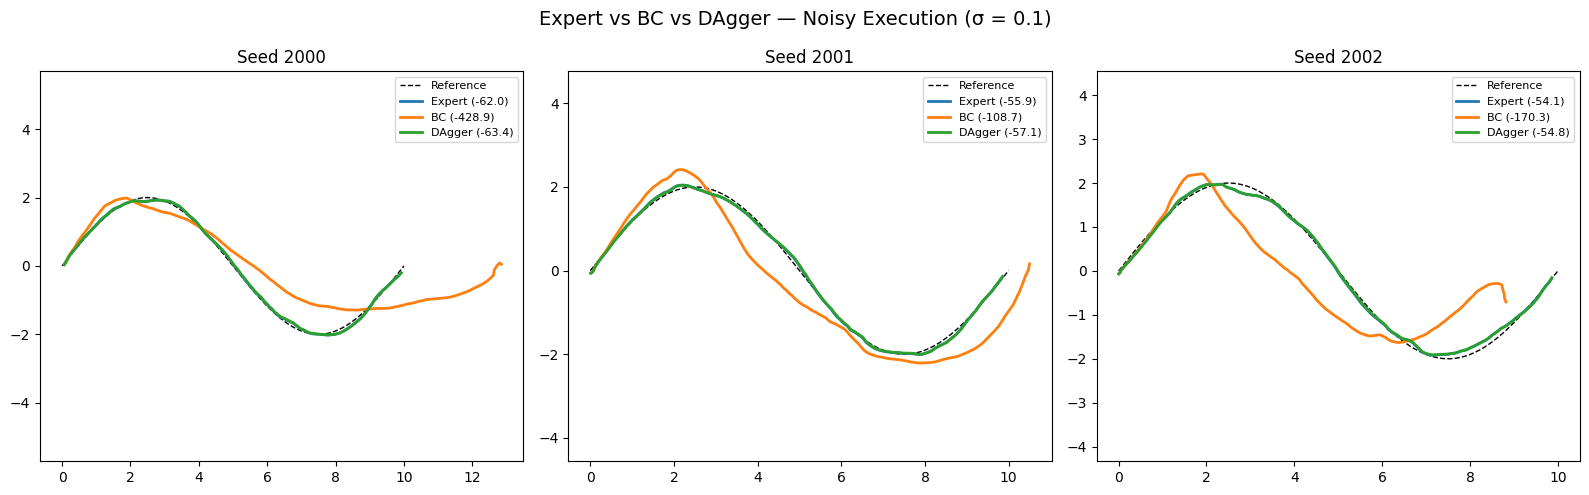

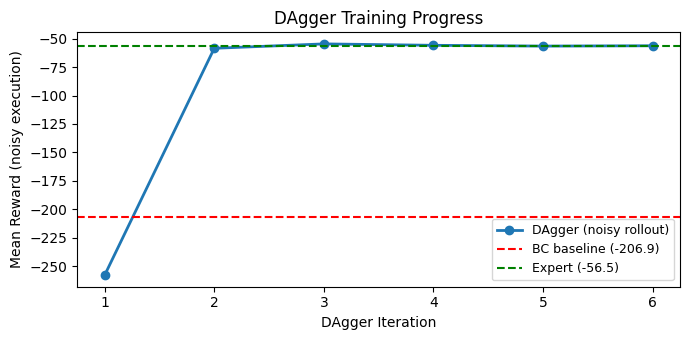

In [16]:
n_eval = 20
dagger_noisy_rews = []
for s in range(n_eval):
    _, dr, _ = rollout_noisy(env, dagger_policy_fn, seed=2000 + s)
    dagger_noisy_rews.append(dr)

print(f"=== Final comparison — noisy execution (σ = {VEL_NOISE_STD}) ===")
print(f"Expert — mean reward: {np.mean(expert_noisy_rews):>8.2f} ± {np.std(expert_noisy_rews):.2f}")
print(f"BC     — mean reward: {np.mean(bc_noisy_rews):>8.2f} ± {np.std(bc_noisy_rews):.2f}")
print(f"DAgger — mean reward: {np.mean(dagger_noisy_rews):>8.2f} ± {np.std(dagger_noisy_rews):.2f}")
print()
bc_gap = np.mean(expert_noisy_rews) - np.mean(bc_noisy_rews)
dag_gap = np.mean(expert_noisy_rews) - np.mean(dagger_noisy_rews)
print(f"Gap to expert:  BC = {bc_gap:.2f},  DAgger = {dag_gap:.2f}")
if abs(bc_gap) > 1e-6:
    print(f"DAgger closes {100 * (1 - dag_gap / bc_gap):.0f}% of the BC→Expert gap.")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
us = np.linspace(0, 1, 300)
ref_path = np.stack([env._path_xy(u) for u in us])

for ax, seed in zip(axes, [2000, 2001, 2002]):
    exp_s, er, _ = rollout_noisy(env, env.expert_policy, seed=seed)
    bc_s, br, _  = rollout_noisy(env, bc_policy_fn, seed=seed)
    dag_s, dr, _ = rollout_noisy(env, dagger_policy_fn, seed=seed)

    ax.plot(ref_path[:, 0], ref_path[:, 1], "k--", lw=1, label="Reference")
    ax.plot(exp_s[:, 0], exp_s[:, 1], lw=2, label=f"Expert ({er:.1f})")
    ax.plot(bc_s[:, 0], bc_s[:, 1], lw=2, label=f"BC ({br:.1f})")
    ax.plot(dag_s[:, 0], dag_s[:, 1], lw=2, label=f"DAgger ({dr:.1f})")
    ax.legend(fontsize=8)
    ax.set_title(f"Seed {seed}")
    ax.axis("equal")

fig.suptitle(
    f"Expert vs BC vs DAgger — Noisy Execution (σ = {VEL_NOISE_STD})",
    fontsize=14,
)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 3.5))
iters = range(1, N_DAGGER_ITERS + 1)
ax.plot(iters, dagger_iter_rewards, "o-", lw=2, label="DAgger (noisy rollout)")
ax.axhline(np.mean(bc_noisy_rews), color="red", ls="--", lw=1.5,
           label=f"BC baseline ({np.mean(bc_noisy_rews):.1f})")
ax.axhline(np.mean(expert_noisy_rews), color="green", ls="--", lw=1.5,
           label=f"Expert ({np.mean(expert_noisy_rews):.1f})")
ax.set_xlabel("DAgger Iteration")
ax.set_ylabel("Mean Reward (noisy execution)")
ax.set_title("DAgger Training Progress")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()